In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

In [2]:
uploaded = files.upload()

Saving MuRIL_Evaluation_Results.csv to MuRIL_Evaluation_Results.csv
Saving Model_Evaluation_Results.csv to Model_Evaluation_Results.csv


In [3]:
ml_results = pd.read_csv("Model_Evaluation_Results.csv")
muril_results = pd.read_csv("MuRIL_Evaluation_Results.csv")

print("Step 8 results:")
display(ml_results)

print("\nMuRIL results:")
display(muril_results)

Step 8 results:


,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,100.0,100.0,100.0,100.0
1,Naive Bayes,100.0,100.0,100.0,100.0
2,Linear SVM,100.0,100.0,100.0,100.0



MuRIL results:


,Model,Accuracy,Precision_Misinformation,Recall_Misinformation,F1_Misinformation
0,MuRIL,1.0,1.0,1.0,1.0


In [4]:
print("ML columns:", ml_results.columns.tolist())
print("MuRIL columns:", muril_results.columns.tolist())

ML columns: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1_Score']
MuRIL columns: ['Model', 'Accuracy', 'Precision_Misinformation', 'Recall_Misinformation', 'F1_Misinformation']


In [5]:
# Standardize Step 8 column names
ml_results.columns = ml_results.columns.str.strip()

# Standardize MuRIL column names
muril_results.columns = muril_results.columns.str.strip()

print("Traditional ML:")
display(ml_results.head())

print("MuRIL:")
display(muril_results.head())

Traditional ML:


,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,100.0,100.0,100.0,100.0
1,Naive Bayes,100.0,100.0,100.0,100.0
2,Linear SVM,100.0,100.0,100.0,100.0


MuRIL:


,Model,Accuracy,Precision_Misinformation,Recall_Misinformation,F1_Misinformation
0,MuRIL,1.0,1.0,1.0,1.0


In [7]:
print("STEP 8 COLUMNS:")
print(ml_results.columns.tolist())

print("\nSTEP 8 DATA:")
display(ml_results)

print("\nSTEP 9 COLUMNS:")
print(muril_results.columns.tolist())

display(muril_results)

STEP 8 COLUMNS:
['Model', 'Accuracy', 'Precision', 'Recall', 'F1_Score']

STEP 8 DATA:


,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,100.0,100.0,100.0,100.0
1,Naive Bayes,100.0,100.0,100.0,100.0
2,Linear SVM,100.0,100.0,100.0,100.0



STEP 9 COLUMNS:
['Model', 'Accuracy', 'Precision_Misinformation', 'Recall_Misinformation', 'F1_Misinformation']


,Model,Accuracy,Precision_Misinformation,Recall_Misinformation,F1_Misinformation
0,MuRIL,1.0,1.0,1.0,1.0


In [8]:
# Step 8: Traditional ML models
ml_comparison = ml_results[
    ["Model", "Accuracy", "Precision", "Recall", "F1_Score"]
].copy()

# Rename F1_Score to F1
ml_comparison.rename(
    columns={"F1_Score": "F1"},
    inplace=True
)

# Step 9: MuRIL Transformer
muril_comparison = pd.DataFrame({
    "Model": ["MuRIL"],
    "Accuracy": [muril_results["Accuracy"].iloc[0] * 100],
    "Precision": [muril_results["Precision_Misinformation"].iloc[0] * 100],
    "Recall": [muril_results["Recall_Misinformation"].iloc[0] * 100],
    "F1": [muril_results["F1_Misinformation"].iloc[0] * 100]
})

# Combine all models
final_comparison = pd.concat(
    [ml_comparison, muril_comparison],
    ignore_index=True
)

# Display comparison
display(final_comparison)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,100.0,100.0,100.0,100.0
1,Naive Bayes,100.0,100.0,100.0,100.0
2,Linear SVM,100.0,100.0,100.0,100.0
3,MuRIL,100.0,100.0,100.0,100.0


In [9]:
final_comparison[
    ["Accuracy", "Precision", "Recall", "F1"]
] = final_comparison[
    ["Accuracy", "Precision", "Recall", "F1"]
].astype(float)

final_comparison = final_comparison.round(2)

display(final_comparison)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,100.0,100.0,100.0,100.0
1,Naive Bayes,100.0,100.0,100.0,100.0
2,Linear SVM,100.0,100.0,100.0,100.0
3,MuRIL,100.0,100.0,100.0,100.0


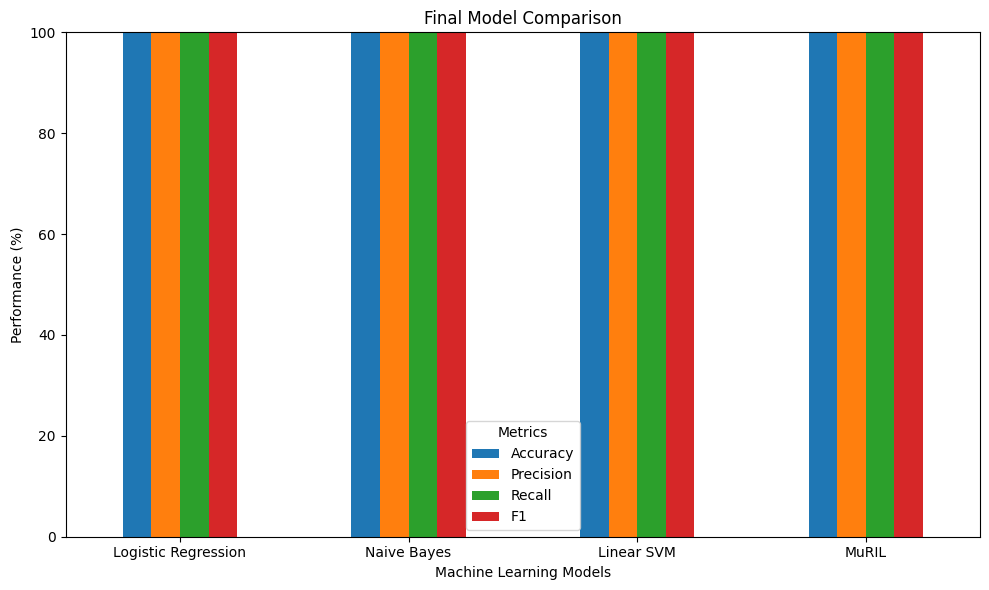

In [10]:
final_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Final Model Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()

plt.savefig("Final_Model_Comparison.png", dpi=300)
plt.show()

In [11]:
final_comparison = final_comparison.sort_values(
    by="F1",
    ascending=False
)

display(final_comparison)

best_model_name = final_comparison.iloc[0]["Model"]

print("Selected Final Model:", best_model_name)
print("Selection criterion: Highest MISINFORMATION F1-score")

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,100.0,100.0,100.0,100.0
1,Naive Bayes,100.0,100.0,100.0,100.0
2,Linear SVM,100.0,100.0,100.0,100.0
3,MuRIL,100.0,100.0,100.0,100.0


Selected Final Model: Logistic Regression
Selection criterion: Highest MISINFORMATION F1-score


In [12]:
final_comparison.to_csv(
    "Final_Model_Comparison.csv",
    index=False
)

selection = pd.DataFrame({
    "Selected_Model": [best_model_name],
    "Selection_Criterion": ["Highest MISINFORMATION F1-score"]
})

selection.to_csv(
    "Final_Model_Selection.csv",
    index=False
)

print("Final model selection saved")

Final model selection saved


In [13]:
files.download("Final_Model_Comparison.csv")
files.download("Final_Model_Selection.csv")
files.download("Final_Model_Comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>